# 02 – Problem Definition & Data Literacy (S2)

**Course section:** Veri Okuryazarlığı (data literacy).

**Goal of this notebook**
1. State the business question and what we will predict.
2. Define the unit of observation, the population and the sample.
3. Build a variable dictionary: role, variable type and measurement scale of every column.
4. Describe the numeric variables with central tendency, dispersion, skewness and kurtosis.
5. Look closely at the target (`price`) to support the choice of success metric.

## 1. Business question

**Context.** A new host in New York City wants to know what nightly price is reasonable for a listing, and which characteristics push the price up or down. A pricing assistant could suggest a price from the listing's location, size, type, host profile and guest reviews.

**Main question (regression).** *How accurately can we estimate the nightly price (USD) of a New York City Airbnb listing from its characteristics, and which characteristics matter most?*

**Second question (classification, S11).** *Which listing and host characteristics are associated with Superhost status?*

**Framing.** The data is a snapshot from early 2021 (COVID period). We estimate **historical** listing prices; the model is not meant to predict today's prices.

## 2. Unit of observation, population and sample

| Concept | In this project |
|---|---|
| **Unit of observation** | One Airbnb listing (one row = one `listing_id`) |
| **Population** | All Airbnb listings offered in New York City around the snapshot date (early 2021) |
| **Sample** | The 37,012 New York listings in the Kaggle file (scraped by Inside Airbnb) |

The file covers almost all listings that were public at scrape time, so it is close to a census of that moment. For the statistics stage (S6) we treat it as a **sample from the NYC short-term rental market process**: the hypothesis tests ask whether a difference is larger than what random variation would produce.

In [1]:
# --- Imports and settings ---
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append(str(Path("..").resolve()))          # make src/ and configs/ importable
from src.data_utils import load_city_listings
from configs.config import RANDOM_STATE, CITY, TARGET

TABLE_DIR = Path("../reports/tables"); TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("../reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

df = load_city_listings(CITY)
print(CITY, df.shape)

New York (37012, 33)


## 3. Variable dictionary

For every column we record:
- **role** – identifier, target, feature, or excluded (with the reason);
- **type** – categorical (nominal / ordinal / binary), numeric (discrete / continuous), date or text;
- **scale** – measurement scale from the course: *nominal, ordinal, interval, ratio*.

The descriptions come from the dataset's `Listings_data_dictionary.csv`; the type, scale and role are our own classification. Counts are computed from the data.

In [2]:
# (description, type, scale, role, note)
meta = {
 "listing_id":        ("Listing ID", "identifier", "nominal", "id", "one row per listing"),
 "name":              ("Listing name", "text", "nominal", "feature (text)", "free text; candidate for S13 text mining"),
 "host_id":           ("Host ID", "identifier", "nominal", "id", "used to check host overlap between train and test"),
 "host_since":        ("Date the host joined Airbnb", "date", "interval", "feature (derived)", "convert to host tenure in days"),
 "host_location":     ("Where the host is based", "categorical", "nominal", "feature (low value)", "free-text location, mostly New York"),
 "host_response_time":("How fast the host usually replies", "categorical", "ordinal", "feature", "within an hour < a few hours < a day < a few days or more"),
 "host_response_rate":("Share of messages the host answers", "numeric continuous", "ratio", "feature", "proportion 0-1"),
 "host_acceptance_rate":("Share of booking requests accepted", "numeric continuous", "ratio", "feature", "proportion 0-1"),
 "host_is_superhost": ("Host has Superhost status (t/f)", "categorical binary", "nominal", "S11 target / feature", "imbalanced"),
 "host_total_listings_count": ("Number of listings the host has", "numeric discrete", "ratio", "feature", "count"),
 "host_has_profile_pic": ("Host has a profile picture (t/f)", "categorical binary", "nominal", "feature", ""),
 "host_identity_verified": ("Host identity verified (t/f)", "categorical binary", "nominal", "feature", ""),
 "neighbourhood":     ("Neighbourhood of the listing", "categorical", "nominal", "feature", "high cardinality"),
 "district":          ("Borough of the listing", "categorical", "nominal", "feature", "5 boroughs"),
 "city":              ("City", "categorical", "nominal", "excluded", "constant after the New York filter"),
 "latitude":          ("Latitude", "numeric continuous", "interval", "feature", "location"),
 "longitude":         ("Longitude", "numeric continuous", "interval", "feature", "location"),
 "property_type":     ("Type of property", "categorical", "nominal", "feature", "high cardinality"),
 "room_type":         ("Entire place / private / shared / hotel room", "categorical", "nominal", "feature", "alternative S11 target"),
 "accommodates":      ("Number of guests the listing fits", "numeric discrete", "ratio", "feature", "count"),
 "bedrooms":          ("Number of bedrooms", "numeric discrete", "ratio", "feature", "count; studios may be missing instead of 0"),
 "amenities":         ("List of amenities", "text (list)", "nominal", "feature (derived)", "amenity count and indicator features"),
 "price":             ("Nightly price in local currency (USD)", "numeric continuous", "ratio", "TARGET", "regression target"),
 "minimum_nights":    ("Minimum nights per booking", "numeric discrete", "ratio", "feature", "count"),
 "maximum_nights":    ("Maximum nights per booking", "numeric discrete", "ratio", "feature", "contains placeholder values"),
 "review_scores_rating":        ("Overall rating (20-100)", "numeric discrete", "ordinal (treated as interval)", "post-stay feature", "missing when no reviews; excluded from primary price model"),
 "review_scores_accuracy":      ("Accuracy score (2-10)", "numeric discrete", "ordinal (treated as interval)", "post-stay feature", "missing when no reviews; excluded from primary price model"),
 "review_scores_cleanliness":   ("Cleanliness score (2-10)", "numeric discrete", "ordinal (treated as interval)", "post-stay feature", "missing when no reviews; excluded from primary price model"),
 "review_scores_checkin":       ("Check-in score (2-10)", "numeric discrete", "ordinal (treated as interval)", "post-stay feature", "missing when no reviews; excluded from primary price model"),
 "review_scores_communication": ("Communication score (2-10)", "numeric discrete", "ordinal (treated as interval)", "post-stay feature", "missing when no reviews; excluded from primary price model"),
 "review_scores_location":      ("Location score (2-10)", "numeric discrete", "ordinal (treated as interval)", "post-stay feature", "missing when no reviews; excluded from primary price model"),
 "review_scores_value":         ("Value-for-money score (2-10)", "numeric discrete", "ordinal (treated as interval)", "post-stay feature", "guests judge value relative to price; excluded from primary price model"),
 "instant_bookable":  ("Can be booked instantly (t/f)", "categorical binary", "nominal", "feature", ""),
}

assert set(meta) == set(df.columns), set(df.columns) ^ set(meta)   # every column documented

var_dict = (pd.DataFrame.from_dict(meta, orient="index",
                                   columns=["description", "type", "scale", "role", "note"])
              .assign(pandas_dtype=df.dtypes.astype(str),
                      n_unique=df.nunique(),
                      pct_missing=(df.isna().mean() * 100).round(2)))
var_dict.index.name = "variable"
var_dict.to_csv(TABLE_DIR / "02_variable_dictionary.csv")
var_dict

,description,type,scale,role,note,pandas_dtype,n_unique,pct_missing
variable,,,,,,,,
listing_id,Listing ID,identifier,nominal,id,one row per listing,int64,37012,0.00
name,Listing name,text,nominal,feature (text),free text; candidate for S13 text mining,str,35625,0.04
host_id,Host ID,identifier,nominal,id,used to check host overlap between train and test,int64,26765,0.00
host_since,Date the host joined Airbnb,date,interval,feature (derived),convert to host tenure in days,str,4000,0.05
host_location,Where the host is based,categorical,nominal,feature (low value),"free-text location, mostly New York",str,1316,0.31
host_response_time,How fast the host usually replies,categorical,ordinal,feature,within an hour < a few hours < a day < a few d...,str,4,50.00
host_response_rate,Share of messages the host answers,numeric continuous,ratio,feature,proportion 0-1,float64,77,50.00
host_acceptance_rate,Share of booking requests accepted,numeric continuous,ratio,feature,proportion 0-1,float64,98,39.54
host_is_superhost,Host has Superhost status (t/f),categorical binary,nominal,S11 target / feature,imbalanced,str,2,0.05


In [3]:
# Summary: how many variables of each type / scale / role?
for col in ["type", "scale", "role"]:
    print(var_dict[col].value_counts().to_string(), "\n")

type
numeric discrete      12
categorical            7
numeric continuous     5
categorical binary     4
identifier             2
text                   1
date                   1
text (list)            1 

scale
nominal                          14
ratio                             8
ordinal (treated as interval)     7
interval                          3
ordinal                           1 

role
feature                 17
post-stay feature        7
id                       2
feature (derived)        2
feature (text)           1
feature (low value)      1
S11 target / feature     1
excluded                 1
TARGET                   1 



### 3.1 Prediction-time feature availability

**Prediction scenario (primary):** a host is creating or re-pricing a listing and wants a price suggestion. Only information that exists **before guests stay** may be used. Guest review scores are created *after* stays, so they are excluded from the primary price model (they can still be used in EDA, in a clearly labelled ablation, and in S11).

In [4]:
availability = {
    "before_stay": ["name", "host_since", "host_location", "host_response_time", "host_response_rate",
                    "host_acceptance_rate", "host_is_superhost", "host_total_listings_count",
                    "host_has_profile_pic", "host_identity_verified", "neighbourhood", "district",
                    "latitude", "longitude", "property_type", "room_type", "accommodates", "bedrooms",
                    "amenities", "minimum_nights", "maximum_nights", "instant_bookable"],
    "after_stay":  [c for c in df.columns if c.startswith("review_scores_")],
    "identifier":  ["listing_id", "host_id"],
    "constant":    ["city"],
    "target":      ["price"],
}
avail_map = {col: k for k, cols in availability.items() for col in cols}
assert set(avail_map) == set(df.columns)

var_dict["availability"] = var_dict.index.map(avail_map)
var_dict["primary_price_model"] = var_dict["availability"].eq("before_stay").map({True: "yes", False: "no"})
var_dict.to_csv(TABLE_DIR / "02_variable_dictionary.csv")

print(var_dict["availability"].value_counts().to_string())
print("\nFeatures allowed in the primary price model:", (var_dict["primary_price_model"] == "yes").sum())
print("Host-level history features (response/acceptance rate, superhost) describe the host's past behaviour,")
print("which exists before a new guest stays, so they are kept.")

availability
before_stay    22
after_stay      7
identifier      2
constant        1
target          1

Features allowed in the primary price model: 22
Host-level history features (response/acceptance rate, superhost) describe the host's past behaviour,
which exists before a new guest stays, so they are kept.


## 4. Central tendency, dispersion and shape of the numeric variables

For each numeric variable (identifiers excluded):
- **central tendency:** mean, median, mode;
- **dispersion:** standard deviation, variance, coefficient of variation (std / mean), range, interquartile range (IQR);
- **shape:** skewness (0 = symmetric, > 0 = long right tail) and excess kurtosis (0 = normal-like tails, > 0 = heavier tails).

Missing values are ignored in each statistic.

In [5]:
num_cols = [c for c in df.select_dtypes("number").columns if var_dict.loc[c, "role"] != "id"]

def describe_numeric(s: pd.Series) -> pd.Series:
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "n": s.size,
        "mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
        "std": s.std(), "variance": s.var(),
        "cv": s.std() / s.mean() if s.mean() != 0 else np.nan,
        "min": s.min(), "max": s.max(), "range": s.max() - s.min(),
        "IQR": q3 - q1,
        "skewness": s.skew(), "kurtosis": s.kurt(),
    })

num_summary = df[num_cols].apply(describe_numeric).T
num_summary.to_csv(TABLE_DIR / "02_numeric_summary.csv")
num_summary.round(3)

,n,mean,median,mode,std,variance,cv,min,max,range,IQR,skewness,kurtosis
host_response_rate,18505.0,0.885,1.000,1.000,2.500000e-01,6.300000e-02,0.283,0.000,1.000000e+00,1.000000e+00,0.100,-2.618,5.953
host_acceptance_rate,22379.0,0.805,0.940,1.000,2.810000e-01,7.900000e-02,0.349,0.000,1.000000e+00,1.000000e+00,0.270,-1.713,2.012
host_total_listings_count,36994.0,23.974,1.000,1.000,1.582250e+02,2.503511e+04,6.600,0.000,2.739000e+03,2.739000e+03,1.000,9.543,99.945
latitude,37012.0,40.730,40.725,40.744,5.500000e-02,3.000000e-03,0.001,40.509,4.091200e+01,4.030000e-01,0.072,0.212,0.186
longitude,37012.0,-73.951,-73.956,-73.972,4.800000e-02,2.000000e-03,-0.001,-74.240,-7.371100e+01,5.290000e-01,0.050,1.331,4.333
accommodates,37012.0,2.798,2.000,2.000,1.846000e+00,3.406000e+00,0.660,0.000,1.600000e+01,1.600000e+01,2.000,2.471,10.136
bedrooms,33404.0,1.316,1.000,1.000,7.220000e-01,5.210000e-01,0.549,1.000,2.100000e+01,2.000000e+01,0.000,3.930,36.144
price,37012.0,142.842,99.000,100.000,2.757410e+02,7.603309e+04,1.930,0.000,1.000000e+04,1.000000e+04,91.000,21.292,651.772
minimum_nights,37012.0,23.324,30.000,30.000,2.644100e+01,6.991400e+02,1.134,1.000,1.250000e+03,1.249000e+03,26.000,14.322,425.230
maximum_nights,37012.0,59799.240,1125.000,1125.000,1.116338e+07,1.246212e+14,186.681,1.000,2.147484e+09,2.147484e+09,1035.000,192.335,36999.163


## 5. The target: `price`

We compare the raw scale with the log scale, because the choice of success metric depends on how skewed the target is.

In [6]:
price = df[TARGET]
print("price == 0          :", (price == 0).sum(), "listings")
print("price > 1,000 USD   :", (price > 1000).sum(), "listings")

pos = price[price > 0]
shape = pd.DataFrame({
    "raw price (USD)": [pos.mean(), pos.median(), pos.std(), pos.skew(), pos.kurt()],
    "log(1 + price)":  [np.log1p(pos).mean(), np.log1p(pos).median(), np.log1p(pos).std(),
                        np.log1p(pos).skew(), np.log1p(pos).kurt()],
}, index=["mean", "median", "std", "skewness", "kurtosis"])
shape.round(3)

price == 0          : 28 listings
price > 1,000 USD   : 236 listings


,raw price (USD),log(1 + price)
mean,142.950,4.631
median,99.000,4.605
std,275.817,0.716
skewness,21.289,0.746
kurtosis,651.509,1.793


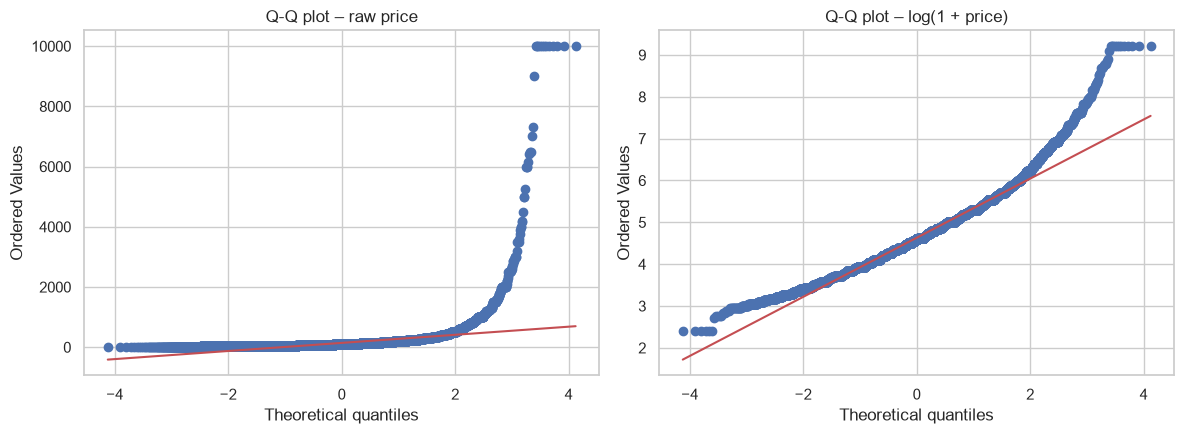

In [7]:
# Q-Q plots: how close is each scale to a normal distribution?
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(pos, dist="norm", plot=axes[0]);  axes[0].set_title("Q-Q plot – raw price")
stats.probplot(np.log1p(pos), dist="norm", plot=axes[1]);  axes[1].set_title("Q-Q plot – log(1 + price)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_price_qq.png", dpi=120, bbox_inches="tight")
plt.show()

In [8]:
# Price level by room type – medians and spread (supports the choice of a robust metric)
(df.loc[df[TARGET] > 0]
   .groupby("room_type")[TARGET]
   .agg(n="size", median="median", mean="mean", std="std",
        p90=lambda s: s.quantile(0.9))
   .round(1)
   .sort_values("median", ascending=False))

,n,median,mean,std,p90
room_type,,,,,
Hotel room,271,163.0,252.2,243.0,440.0
Entire place,19397,140.0,191.5,283.9,300.0
Private room,16630,60.0,86.3,245.7,125.0
Shared room,686,45.0,101.0,431.8,150.0


In [9]:
# Naive baseline errors: what error does "always predict the median" give?
# This is the reference every model must beat (computed here on the full data only as an illustration;
# the real baseline will be computed on the training folds in S8).
med = pos.median()
mae_usd = (pos - med).abs().mean()
rmse_usd = np.sqrt(((pos - med) ** 2).mean())
rmse_log = np.sqrt(((np.log1p(pos) - np.log1p(med)) ** 2).mean())
print(f"Median price           : {med:.0f} USD")
print(f"Baseline MAE  (USD)    : {mae_usd:.1f}")
print(f"Baseline RMSE (USD)    : {rmse_usd:.1f}")
print(f"Baseline RMSE (log)    : {rmse_log:.3f}")

Median price           : 99 USD
Baseline MAE  (USD)    : 81.4
Baseline RMSE (USD)    : 279.3
Baseline RMSE (log)    : 0.717


## 6. Classification target candidate: `host_is_superhost`

In [10]:
sh = df["host_is_superhost"]
print(sh.value_counts(dropna=False).to_string())
print("\nShare of Superhosts:", round((sh == "t").mean(), 3))

# Superhost status is granted by Airbnb using rating, response rate and number of stays.
# Check how strongly these candidate features differ between the two classes.
(df.groupby("host_is_superhost")[["review_scores_rating", "host_response_rate",
                                   "host_acceptance_rate", "host_total_listings_count"]]
   .median().round(3))

host_is_superhost
f      30023
t       6971
NaN       18

Share of Superhosts: 0.188


,review_scores_rating,host_response_rate,host_acceptance_rate,host_total_listings_count
host_is_superhost,,,,
f,96.0,1.0,0.93,1.0
t,98.0,1.0,0.94,2.0


## 7. Missing data: first hypotheses about the mechanism

Course terms: **MCAR** (missing completely at random), **MAR** (missingness explained by other observed variables), **MNAR** (missingness depends on the missing value itself). These are *hypotheses* to test in S7, not proven facts.

In [11]:
no_reviews = df["review_scores_rating"].isna()          # proxy: listing has no review scores
resp_missing = df["host_response_rate"].isna()
check = pd.DataFrame({
    "host_response_rate missing": [resp_missing[no_reviews].mean(), resp_missing[~no_reviews].mean()],
    "host_acceptance_rate missing": [df.loc[no_reviews, "host_acceptance_rate"].isna().mean(),
                                     df.loc[~no_reviews, "host_acceptance_rate"].isna().mean()],
    "bedrooms missing": [df.loc[no_reviews, "bedrooms"].isna().mean(), df.loc[~no_reviews, "bedrooms"].isna().mean()],
}, index=["listings without review scores", "listings with review scores"]).round(3)
print("Share missing, split by whether the listing has review scores:")
display(check)

# The 18 rows with missing host fields: are they the same rows?
host_cols = ["host_since", "host_is_superhost", "host_total_listings_count", "host_has_profile_pic", "host_identity_verified"]
print("Rows where ALL 5 host fields are missing:", df[host_cols].isna().all(axis=1).sum())

Share missing, split by whether the listing has review scores:


,host_response_rate missing,host_acceptance_rate missing,bedrooms missing
listings without review scores,0.525,0.505,0.105
listings with review scores,0.490,0.353,0.095


Rows where ALL 5 host fields are missing: 18


| Variable(s) | % missing | Hypothesis | How we will check / treat (S7) |
|---|---|---|---|
| `review_scores_*` (7) | ~27.7% | **Structural**: no reviews → no scores (verified in notebook 01: 100% missing without reviews vs 2.6% with reviews) | Not a data error; excluded from the primary price model anyway; "has reviews" flag for S11 |
| `host_response_time`, `host_response_rate` | 50.0% (always together) | Unclear. The "inactive listing" idea is **not supported** by the table above: 52.5% missing for listings without reviews vs 49.0% with reviews. Could be a scraping/platform effect | Test against other variables (host tenure, room type, borough); missing-indicator + imputation |
| `host_acceptance_rate` | 39.5% | **MAR** (plausible): more often missing when the listing has no reviews (50.5% vs 35.3%), i.e. fewer booking requests | Missing-indicator + imputation; compare methods in S7 |
| `bedrooms` | 9.75% | Possibly **MNAR / coding**: smallest observed value is 1, so studios (0 bedrooms) may be stored as missing | Check against property type, `accommodates` and listing names ("studio") |
| 5 host fields | 0.05% (18 rows) | Always missing together in the same 18 rows → probably deleted or incomplete host profiles | Small; decided in S7 |

## 8. Target definition and modeling subsets

In [12]:
# Verify the zero-price listings before excluding them from the regression target
zero = df[df[TARGET] == 0]
print("Zero-price listings:", len(zero))
print(zero["room_type"].value_counts().to_string())
print("\nDistinct hosts:", zero["host_id"].nunique())
display(zero[["host_id", "name", "property_type", "neighbourhood", "accommodates", "minimum_nights"]].head(10))

Zero-price listings: 28
room_type
Hotel room    28

Distinct hosts: 28


,host_id,name,property_type,neighbourhood,accommodates,minimum_nights
28607,300800542,Hotel Hugo,Room in boutique hotel,SoHo,0,30
28608,324955773,Hotel 57,Room in boutique hotel,Midtown,0,30
28739,335389657,Wellington Hotel,Room in boutique hotel,Midtown,0,1
28740,360662584,"The Standard, East Village",Room in boutique hotel,East Village,0,1
28741,372762243,Hotel Scherman,Room in boutique hotel,Hell's Kitchen,0,1
28742,374516933,citizenM New York Bowery,Room in boutique hotel,Lower East Side,0,1
28865,318753867,Doxie Hotel,Room in hotel,Midtown,4,1
28923,268417148,The James New York - NoMad,Room in boutique hotel,Midtown,4,1
28924,197053492,Mint House At 70 Pine,Room in boutique hotel,Financial District,6,1
28925,307633956,Artezen Hotel,Room in hotel,Financial District,4,30


In [13]:
subsets = pd.Series({
    "Observed dataset (New York)": len(df),
    "Regression modeling subset (price > 0)": int((df[TARGET] > 0).sum()),
    "Classification subset (host_is_superhost not missing)": int(df["host_is_superhost"].notna().sum()),
}, name="rows")
subsets.to_frame()

,rows
Observed dataset (New York),37012
Regression modeling subset (price > 0),36984
Classification subset (host_is_superhost not missing),36994


**Population → observed data → modeling subsets**

- *Population:* all NYC Airbnb listings around early 2021.
- *Observed dataset:* 37,012 listings (Inside Airbnb scrape, via Kaggle).
- *Regression subset:* listings with `price > 0`. The 28 zero-price rows are all hotel rooms from 28 different hotels (named hotel pages, several with `accommodates = 0`): placeholder listings, not free stays. They are kept in the raw file and in descriptive EDA, and their removal is documented.
- *Classification subset:* listings with a known `host_is_superhost` value.
- Listings priced above 1,000 USD (236) stay in for now; how to treat them is decided in S7.

**Why log(1 + price)?** Raw price has skewness 21.3 and kurtosis 651.5; on the log scale they drop to 0.75 and 1.79 and the Q-Q plot is close to a straight line. Prices act multiplicatively (a bigger flat in Manhattan costs *x times* more, not *x dollars* more), so errors in percentage terms are the natural unit.

**What we estimate (estimand).** Models trained with squared error on log(1 + price) estimate the mean of log price. Back-transforming with `expm1` gives approximately the **typical (median) price** of listings with the same characteristics, not the mean price in USD. This is why the USD metrics we report are MAE and median absolute error. A smearing correction (Duan) is optional and would only be estimated on training folds.

## 9. Success metrics

**Regression (price)**
| Role | Metric | Scale |
|---|---|---|
| Primary (model selection) | RMSE of log(1 + price) | log |
| Secondary | MAE | USD, after `expm1` |
| Additional | Median absolute error | USD, after `expm1` |
| Diagnostic | R² | log |
| Diagnostic | RMSE | USD, shows errors on expensive listings |

- Every model uses the **same CV folds, random_state and preprocessing rules**.
- The baseline is a `DummyRegressor(strategy="median")` evaluated **inside the same CV** (the 0.717 above is only an illustration).
- Aspirational target: at least **30% lower log-RMSE than the baseline**. If it is not reached we report it as it is and do not change the rules after seeing results.

**Classification (`host_is_superhost`)**
- Primary: ROC-AUC. Secondary: PR-AUC, recall and F1 for the Superhost class. Accuracy only next to the 81.2% majority baseline.
- Stratified splits; two feature sets: (1) all allowed features, (2) without review scores and host response/acceptance rates, because Airbnb's own Superhost rules use them.

## 10. Limitations
- **Historical snapshot (early 2021, COVID period):** results describe that market, not today's prices.
- **Observational data:** relationships are associations, not causal effects (e.g. "Superhosts charge more" does not mean becoming a Superhost raises price).
- **Listed price, not paid price:** the dataset has the advertised nightly price; discounts, cleaning fees and seasonal prices are not included.
- **Host clustering:** some hosts own many listings (max 2,739); random CV may be optimistic if a host's listings appear in both training and validation folds. This is checked in S8.
- **Review scores are post-stay:** excluded from the primary price model to avoid leakage.

## 11. Evaluation of S2

**What we did**
- Defined the business question, the unit of observation (one listing), the population and the modeling subsets.
- Built a variable dictionary for all 33 columns with type, measurement scale, role and prediction-time availability (`reports/tables/02_variable_dictionary.csv`).
- Described every numeric variable with central tendency, dispersion, skewness and kurtosis (`reports/tables/02_numeric_summary.csv`).
- Analysed the target and wrote first hypotheses about the missing-data mechanisms.

**Key findings**
- `price` is extremely right-skewed (skewness 21.3, kurtosis 651.5); on the log scale it is close to symmetric (0.75 / 1.79) → we model `log(1 + price)`.
- The 28 zero-price rows are placeholder pages of 28 different hotels, not free stays.
- Review scores exist only after guests stay → they cannot be used to suggest a price for a new listing.
- One missing-data hypothesis was **not** supported: `host_response_rate` is missing about equally often with and without reviews (52.5% vs 49.0%).
- Superhost and non-Superhost listings have close medians on rating, response and acceptance rate, so the classification task is not trivially solved by one variable.

**Decisions (reviewed by ChatGPT in REVIEW #4, approved by the student)**
| ID | Decision |
|---|---|
| D3 | Business question: estimate the historical nightly price of an NYC listing from characteristics known before guests stay; secondary: what is associated with Superhost status |
| D4 | Target `price` (USD), modeled as `log(1 + price)`, read as the typical (median) price; the 28 zero-price rows are excluded from regression only (36,984 rows); listings above 1,000 USD are decided in S7 |
| D5 | Primary metric log-RMSE (cross-validated); MAE and median absolute error in USD; R² (log) and RMSE (USD) as diagnostics; median baseline inside the same CV; aspirational target ≥ 30% better than the baseline |
| D6 | S11 target `host_is_superhost` (36,994 rows); ROC-AUC primary, PR-AUC / recall / F1 secondary; stratified; full vs reduced feature set |
| D7 | Primary price model uses the 22 before-stay features; IDs, `city` and the 7 review scores are excluded (review scores tested only in an ablation) |

**Next step:** S3 – environment and repository (reusable `src/` functions, a small class with error handling, light tests, README update).
